# Demo Live Inference pada Foto Baru (Tanpa Anotasi)

<table>
  <tr><td><b>Nama</b></td><td>Shabrina Sarayati</td></tr>
  <tr><td><b>NRP</b></td><td>5054241009</td></tr>
  <tr><td><b>Mata Kuliah</b></td><td>Visi Komputer</td></tr>
</table>


In [ ]:
# 1. Install library (jika belum ada), Mount Google Drive, & Load 3 Model Terbaik
import importlib.util, subprocess, sys
for _pkg in ["ultralytics", "transformers"]:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import os, torch, torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import drive, files
from torchvision.transforms import functional as TF
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from ultralytics import YOLO
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE_DIR = "/content/drive/MyDrive/Visi Komputer/Tugas2"
ALL_CLS_DIR = os.path.join(BASE_DIR, "baseline_all_classes")

# Urutan 75 kategori COCO yang dipakai saat training Mask R-CNN & Mask2Former
COCO_75_CLASSES = ["indoor-objects", "backpack", "bed", "blanket", "book", "bottle", "bowl", "box", "cabinet-merged", "cardboard", "ceiling-merged", "cell phone", "chair", "clock", "couch", "counter", "cup", "curtain", "dining table", "door-stuff", "fire-extinguisher", "floor-other-merged", "floor-wood", "flower", "food-other-merged", "fork", "hair drier", "handbag", "keyboard", "knife", "laptop", "light", "microwave", "mirror-stuff", "mouse", "oven", "pan", "paper", "paper-merged", "person", "pillow", "plate", "plug", "potted plant", "refrigerator", "remote", "rug-merged", "scissor", "scissors", "shelf", "sink", "spoon", "st-", "stairs", "stove-merged", "table-merged", "teddy bear", "toaster", "toilet", "toothbrush", "towel", "toy", "trash-bin", "tree-merged", "tv", "vase", "wall", "wall-brick", "wall-other-merged", "wall-stone", "wall-tile", "wall-wood", "wallet", "window-blind", "window-other"]

# 1) Load YOLOv8s-seg
demo_yolo = YOLO(os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "train", "weights", "best.pt"))

# 2) Load Mask R-CNN (75 kelas + 1 background = 76)
demo_mrcnn = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
demo_mrcnn.roi_heads.box_predictor = FastRCNNPredictor(demo_mrcnn.roi_heads.box_predictor.cls_score.in_features, len(COCO_75_CLASSES) + 1)
demo_mrcnn.roi_heads.mask_predictor = MaskRCNNPredictor(demo_mrcnn.roi_heads.mask_predictor.conv5_mask.in_channels, 256, len(COCO_75_CLASSES) + 1)
demo_mrcnn.load_state_dict(torch.load(os.path.join(ALL_CLS_DIR, "02_maskrcnn", "best_maskrcnn.pth"), map_location=device))
demo_mrcnn.to(device).eval()

# 3) Load Mask2Former
m2f_dir = os.path.join(ALL_CLS_DIR, "03_mask2former", "best_mask2former")
demo_m2f_proc = Mask2FormerImageProcessor.from_pretrained(m2f_dir)
demo_m2f = Mask2FormerForUniversalSegmentation.from_pretrained(m2f_dir).to(device).eval()

print("Ketiga model berhasil dimuat di:", device)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Ketiga model berhasil dimuat di: cpu


Foto dimuat: foto_demo_baru.jpg | Ukuran asli: 768x1024 -> Inferensi: 768x1024 | CONF_THRESH = 0.3


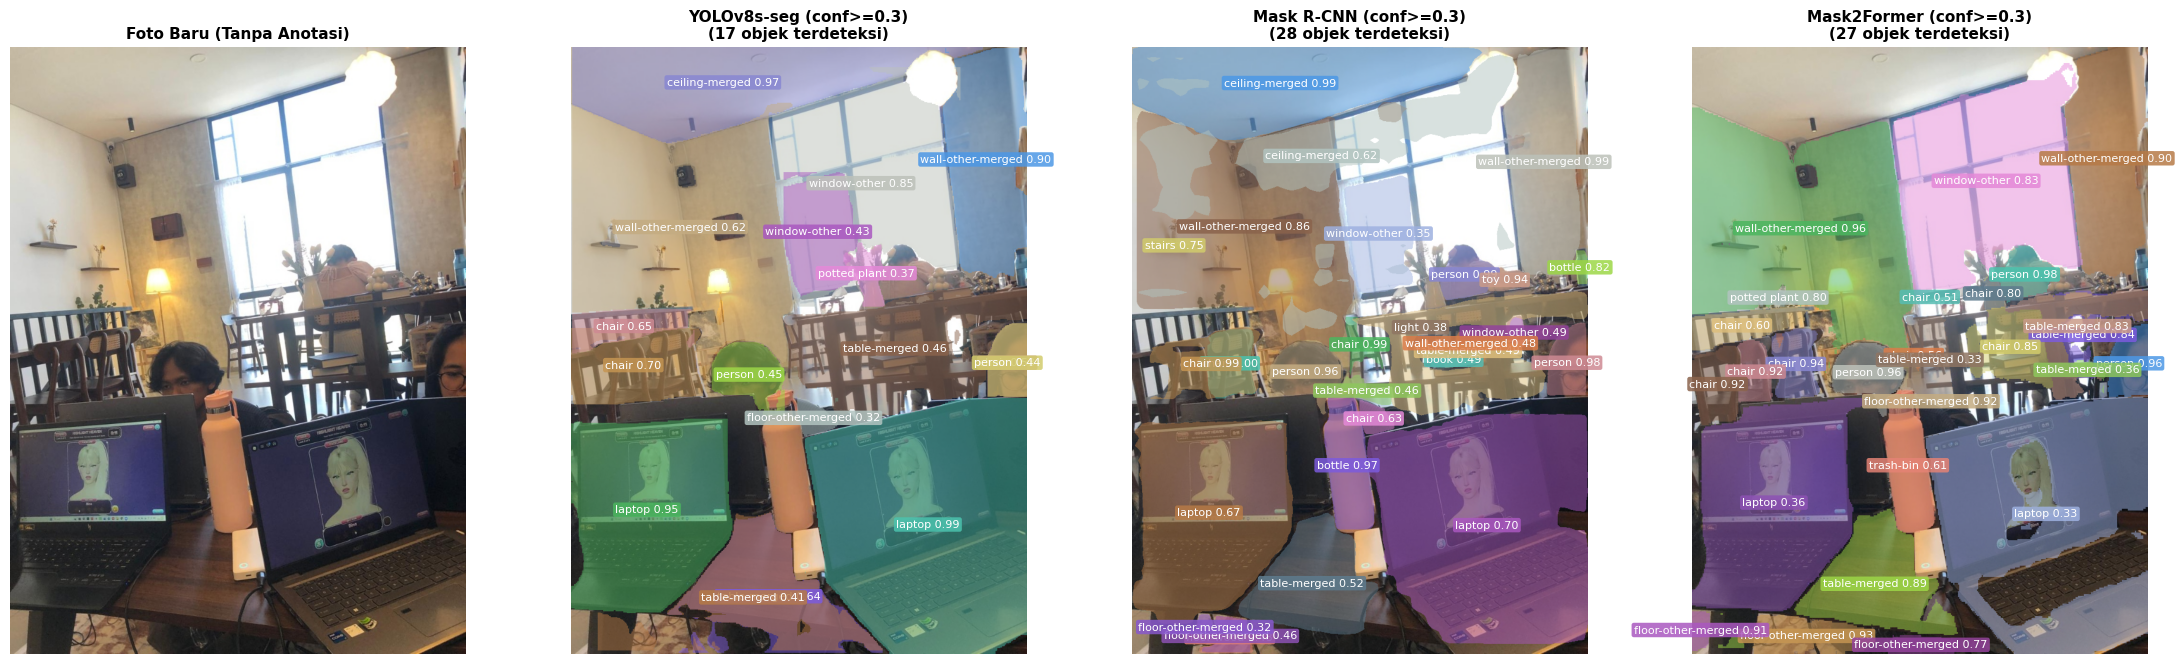


=== RINGKASAN OBJEK TERDETEKSI ===
- YOLOv8s-seg  [17 objek]: laptop (0.99), ceiling-merged (0.97), laptop (0.95), wall-other-merged (0.90), window-other (0.85), chair (0.70), chair (0.65), table-merged (0.64), wall-other-merged (0.62), chair (0.53), table-merged (0.46), person (0.45), person (0.44), window-other (0.43), table-merged (0.41), potted plant (0.37), floor-other-merged (0.32)
- Mask R-CNN   [28 objek]: chair (1.00), person (0.99), chair (0.99), ceiling-merged (0.99), wall-other-merged (0.99), chair (0.99), person (0.98), bottle (0.97), person (0.96), toy (0.94), wall-other-merged (0.86), bottle (0.82), stairs (0.75), laptop (0.70), laptop (0.67), chair (0.63), ceiling-merged (0.62), table-merged (0.52), window-other (0.49), book (0.49), table-merged (0.49), floor-wood (0.48), wall-other-merged (0.48), table-merged (0.46), floor-other-merged (0.46), light (0.38), window-other (0.35), floor-other-merged (0.32)
- Mask2Former  [27 objek]: person (0.98), chair (0.94), wall-othe

In [ ]:
# 2. Inferensi Langsung pada Foto Baru (Belum Dianotasi)
CONF_THRESH = 0.30     # <-- UBAH ANGKA INI JIKA DIMINTA GANTI CONFIDENCE THRESHOLD (misal 0.15 atau 0.50)
UPLOAD_MANUAL = False  # <-- Ubah jadi True jika ingin upload file foto lain dari laptop/HP

if UPLOAD_MANUAL:
    up = files.upload()
    IMG_PATH = list(up.keys())[0]
else:
    IMG_PATH = os.path.join(BASE_DIR, "foto_demo_baru.jpg")

img_orig = ImageOps.exif_transpose(Image.open(IMG_PATH)).convert("RGB")
w0, h0 = img_orig.size
# Batasi sisi terpanjang maks 1024 px agar cepat & bebas CUDA OutOfMemoryError
scale = min(1.0, 1024.0 / max(w0, h0))
img_pil = img_orig.resize((int(w0 * scale), int(h0 * scale)), Image.BILINEAR) if scale < 1.0 else img_orig
img_np = np.array(img_pil)
w, h = img_pil.size
print(f"Foto dimuat: {os.path.basename(IMG_PATH)} | Ukuran asli: {w0}x{h0} -> Inferensi: {w}x{h} | CONF_THRESH = {CONF_THRESH}")

# --- Prediksi 1: YOLOv8s-seg ---
yr = demo_yolo.predict(img_np, imgsz=640, conf=CONF_THRESH, verbose=False)[0]
ym, yl, ys = [], [], []
if yr.masks is not None:
    for mk, c, s in zip(yr.masks.data.cpu().numpy(), yr.boxes.cls.cpu().numpy(), yr.boxes.conf.cpu().numpy()):
        m_bin = np.array(Image.fromarray((mk > 0.5).astype(np.uint8) * 255).resize((w, h), Image.NEAREST)) > 127
        if m_bin.sum() > 0:
            ym.append(m_bin)
            yl.append(demo_yolo.names[int(c)])
            ys.append(float(s))

# --- Prediksi 2: Mask R-CNN ---
with torch.no_grad():
    mo = demo_mrcnn([TF.to_tensor(img_pil).to(device)])[0]
rm, rl, rs = [], [], []
for s, lb, mk in zip(mo["scores"].cpu().numpy(), mo["labels"].cpu().numpy(), mo["masks"].cpu().numpy()):
    if s >= CONF_THRESH and 1 <= int(lb) <= len(COCO_75_CLASSES):
        m_bin = mk[0] > 0.5
        if m_bin.sum() > 0:
            rm.append(m_bin)
            rl.append(COCO_75_CLASSES[int(lb) - 1])
            rs.append(float(s))

# --- Prediksi 3: Mask2Former ---
inp = demo_m2f_proc(images=[img_pil], return_tensors="pt")
with torch.no_grad():
    fo = demo_m2f(pixel_values=inp["pixel_values"].to(device), pixel_mask=inp["pixel_mask"].to(device))
fr = demo_m2f_proc.post_process_instance_segmentation(fo, threshold=CONF_THRESH, target_sizes=[(h, w)])[0]
seg = fr["segmentation"].cpu().numpy()
fm, fl, fs = [], [], []
for info in fr["segments_info"]:
    lid = int(info["label_id"])
    if 0 <= lid < len(COCO_75_CLASSES):
        m_bin = seg == info["id"]
        if m_bin.sum() > 0:
            fm.append(m_bin)
            fl.append(COCO_75_CLASSES[lid])
            fs.append(float(info["score"]))

# --- Visualisasi 4 Panel ---
def draw_pred(ax, base_np, masks, labels, scores, title):
    rng = np.random.default_rng(42)
    ov = base_np.copy().astype(np.float32)
    items = []
    for m, lb, sc in zip(masks, labels, scores):
        col = rng.integers(60, 235, size=3)
        ov[m] = ov[m] * 0.5 + col * 0.5
        ys_i, xs_i = np.where(m)
        items.append((int(xs_i.mean()), int(ys_i.mean()), f"{lb} {sc:.2f}", tuple((col / 255.0).tolist())))
    ax.imshow(ov.astype(np.uint8))
    for cx, cy, txt, c in items:
        ax.text(cx, cy, txt, fontsize=8, color="white", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=c, alpha=0.85, edgecolor="none"))
    ax.set_title(f"{title}\n({len(items)} objek terdeteksi)", fontsize=11, fontweight="bold")
    ax.axis("off")

fig, axes = plt.subplots(1, 4, figsize=(22, 7))
axes[0].imshow(img_np)
axes[0].set_title("Foto Baru (Tanpa Anotasi)", fontsize=11, fontweight="bold")
axes[0].axis("off")
draw_pred(axes[1], img_np, ym, yl, ys, f"YOLOv8s-seg (conf>={CONF_THRESH})")
draw_pred(axes[2], img_np, rm, rl, rs, f"Mask R-CNN (conf>={CONF_THRESH})")
draw_pred(axes[3], img_np, fm, fl, fs, f"Mask2Former (conf>={CONF_THRESH})")

plt.tight_layout()
out_png = os.path.join(BASE_DIR, "hasil_demo_foto_baru.png")
plt.savefig(out_png, dpi=180, bbox_inches="tight")
plt.show()

# Ringkasan tabel objek yang terdeteksi tiap model
print("\n=== RINGKASAN OBJEK TERDETEKSI ===")
for mname, lbs, scs in [("YOLOv8s-seg", yl, ys), ("Mask R-CNN", rl, rs), ("Mask2Former", fl, fs)]:
    det_str = ", ".join([f"{l} ({s:.2f})" for l, s in zip(lbs, scs)]) if lbs else "Tidak ada prediksi di atas threshold"
    print(f"- {mname:12s} [{len(lbs):2d} objek]: {det_str}")


In [ ]:
# 3. (Opsional Saat Tanya Jawab) Cek Skor Mask AP untuk Satu Kelas Tertentu
KELAS_DICARI = "laptop"  # <-- Ganti misal: "chair", "bottle", "person", "table-merged", "pillow"

df_cls = pd.read_csv(os.path.join(ALL_CLS_DIR, "combined_per_class_ap_test.csv"))
print(f"=== Skor Mask AP@50-95 Kelas '{KELAS_DICARI}' pada Test Set Asli ===")
print(df_cls[df_cls["class_name"] == KELAS_DICARI].to_string(index=False))


=== Skor Mask AP@50-95 Kelas 'laptop' pada Test Set Asli ===
class_name  gt_instances  mrcnn_ap  m2f_ap  yolo_ap  mean_ap
    laptop            27    0.3863  0.1231   0.3609   0.2901
